In [2]:
import geopandas as gpd

aoi_polygon = gpd.read_file("inputs/AoI_Polygons/AoI_topobathy.shp").loc[0, "geometry"]
aoi_polygon

In [3]:
import regionmask

my_region = regionmask.Regions([aoi_polygon], name="my_region")
my_region

<regionmask.Regions 'my_region'>
overlap:  None

Regions:
0 r0 Region0

[1 regions]

In [9]:
from utils.simulations import generate_cases

goals_config = {
    1: {"lat": 36.5625, "lon": -75.5, "angles": [-80, 170]},
    2: {"lat": 36.125, "lon": -75.25, "angles": [-70, 120]},
    3: {"lat": 35.6875, "lon": -75.0625, "angles": [-90, 100]},
    4: {"lat": 35.3125, "lon": -75.0625, "angles": [-120, 90]},
    5: {"lat": 34.9375, "lon": -75.375, "angles": [-135, 45]},
    6: {"lat": 34.75, "lon": -75.75, "angles": [-130, 45]},
    7: {"lat": 34.5, "lon": -76.0625, "angles": [-130, 45]},
    8: {"lat": 34.1875, "lon": -76.4375, "angles": [-130, 45]},
    9: {"lat": 34.03125, "lon": -76.96875, "angles": [-130, 45]},
    10: {"lat": 33.6875, "lon": -77.4375, "angles": [-130, 45]},
    11: {"lat": 33.40625, "lon": -77.84375, "angles": [-130, 45]},
    12: {"lat": 33.1875, "lon": -78.25, "angles": [-130, 45]},
    13: {"lat": 33, "lon": -78.625, "angles": [-130, 45]},
    14: {"lat": 32.875, "lon": -79, "angles": [-225, 45]},
}
cases_df = generate_cases(goals_config, num_samples_per_goal=10)
cases_df

,goal,tp,wd,ds,zs
0,1,8.683450,93.761592,39.965698,-2.764055
1,1,1.963436,130.583161,10.558109,2.513561
2,1,10.030569,305.688978,6.484542,-0.376700
3,1,6.138376,299.710718,26.065943,3.182551
4,1,14.812342,30.077825,22.104797,0.516381
...,...,...,...,...,...
135,14,11.149489,106.571036,3.265160,-1.386516
136,14,6.653680,145.569328,33.818602,-1.593824
137,14,4.975087,260.187986,29.529298,1.318894
138,14,12.727114,308.970444,42.302785,-3.442108


<Axes: xlabel='tp', ylabel='wd'>

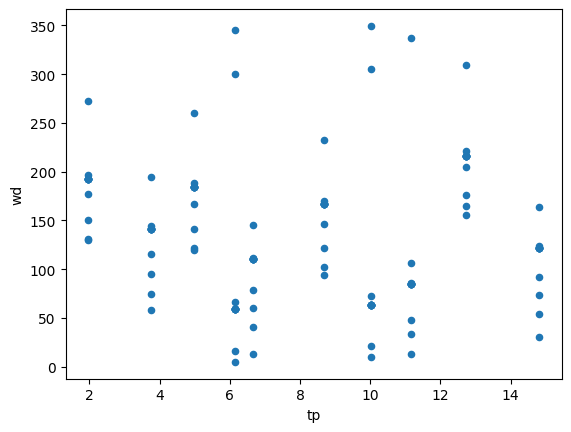

In [10]:
cases_df.plot.scatter(x="tp", y="wd")

In [11]:
from bluemath_tk.wrappers.snapwave.snapwave_wrapper import SnapWaveModelWrapper

snapwave_wrapper = SnapWaveModelWrapper(
    templates_dir="templates-metamodel",
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={},
    output_dir="SnapWave_CASES_METAMODEL",
    region_of_interest=my_region,
    goals_config=goals_config,
)
snapwave_wrapper

2026-06-10 16:03:44,368 - SnapWaveModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-06-10 16:03:44,368 - SnapWaveModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-06-10 16:03:44,368 - SnapWaveModelWrapper - WARNING - Parameter wd is not in the default_parameters
2026-06-10 16:03:44,369 - SnapWaveModelWrapper - WARNING - Parameter ds is not in the default_parameters
2026-06-10 16:03:44,369 - SnapWaveModelWrapper - WARNING - Parameter zs is not in the default_parameters


In [12]:
snapwave_wrapper.calculate_output_grid_parameters(output_grid_resolution=0.01)

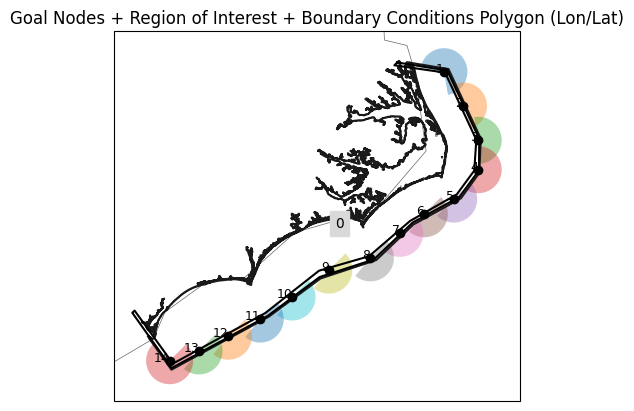

In [13]:
snapwave_wrapper.plot_configuration()

In [14]:
snapwave_wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [15]:
snapwave_wrapper.run_cases_in_background(launcher="default", cases_to_run=[0])

2026-06-10 16:04:57,610 - SnapWaveModelWrapper - WARNING - Cases to run was specified, so just [0] will be run.


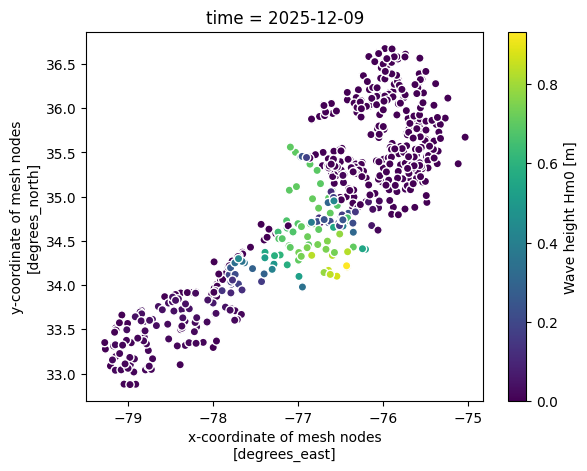

In [19]:
import xarray as xr

xr.open_dataset("SnapWave_CASES_METAMODEL/08/0074/mesh.nc").isel(
    nmesh2d_node=slice(None, None, 100)
).squeeze().plot.scatter(x="mesh2d_node_x", y="mesh2d_node_y", hue="hm0")

In [10]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    20000
Name: count, dtype: int64

In [11]:
result_msg = snapwave_wrapper.postprocess_cases()
result_msg

'Olrait!'